# The WordPress import: a profile, its topics, its claims and its entities

The 187 published posts of `inspiringnews-buenasnoticias.WordPress.2026-11-03.xml`, as the **positive** graph holds them
(`source_id = wordpress:inspiringnews.ai`). **Nothing is verified and nothing is written to the graph.** The import ran
with `verify=false` on 3 Nov 2026, so every post has its topics, entities and claims and no verdict. Every post is
kept, including the 28 that admission would have turned away.

**Two sets of labels, side by side:**

- **The dump's own:** each post's WordPress categories (8) and tags (169 distinct), read from the import's snapshot of the file.
- **Ours:** the pipeline's 23 topics in 5 groups, as the topic classifier gave them, plus the topics the WordPress tags
  and categories point to through an explicit mapping table (section 4), which you can edit. A post the classifier gave
  no topic gets its **closest topic** from that mapping.

**Words used:**

- **Category** is the post's WordPress category. Its *section* is the first segment of its URL (`/ciencia/...`), the one
  category the site files it under; 23 posts carry more than one category.
- **Main topic** is the classifier's rank 1.
- **A name** is an entity with a capital letter and at least two characters (the news map's rule). Common nouns
  that GLiNER labelled as people ("investigadores"), the site's own name and the "Fuentes" heading are profiled, then left
  out of the interaction analysis.

**Run it:**

```bash
cd research && uv sync && uv run jupyter lab wordpress-import/wordpress_import.ipynb
```

It reads Neo4j when it is up (`docker compose up -d neo4j`; credentials from `backend/.env`) and otherwise
`data/graph-export.json`, the last read. Section 8 writes `data/wordpress-labels.json`, which the news map reads to
show WordPress labels and to place the posts our classifier left without a topic.

In [1]:
from __future__ import annotations

import json
import re
import sys
import unicodedata
from collections import Counter, defaultdict
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

HERE = Path.cwd() if (Path.cwd() / "wordpress_import.ipynb").exists() else Path.cwd() / "wordpress-import"
ROOT = HERE.parent.parent
BACKEND = ROOT / "backend"
DATA = HERE / "data"
DATA.mkdir(exist_ok=True)

IMPORT_DIR = BACKEND / "data" / "imports" / "inspiringnews-buenasnoticias.WordPress.2026-11-03"
SOURCE_ID = "wordpress:inspiringnews.ai"

# Our taxonomy, from the backend itself so the two cannot drift (a plain dataclass, no dependencies).
sys.path.insert(0, str(BACKEND))
from src.config.topics import GROUP_OF, TOPIC_GROUP_NAMES, TOPIC_GROUPS, TOPICS  # noqa: E402

TOPIC_NAME = {key: topic.name for key, topic in TOPICS.items() if key in GROUP_OF}
KEY_OF_NAME = {name: key for key, name in TOPIC_NAME.items()}
GROUPS = list(TOPIC_GROUPS)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pio.renderers.default = "plotly_mimetype+notebook_connected"

# Colours: the dataviz reference palette. One hue (blue) for amounts; the categorical slots in fixed order for kinds.
BLUE = "#2a78d6"
GREY = "#b9b7ae"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
KINDS = ["people", "organisations", "places", "products", "events"]
KIND_COLOR = dict(zip(KINDS, SLOTS))
KIND_OF = {"person": "people", "organization": "organisations", "company": "organisations",
           "country": "places", "city": "places", "location": "places", "product": "products", "event": "events"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": INK2, "font.size": 10, "font.family": "sans-serif",
})


def fold(text: str) -> str:
    plain = "".join(c for c in unicodedata.normalize("NFKD", str(text)) if not unicodedata.combining(c))
    return " ".join(plain.casefold().split())


def proper_name(name: str) -> bool:
    name = (name or "").strip()
    return len(name) >= 2 and any(ch.isupper() for ch in name)


def hbar(ax, labels, values, title, color=BLUE, fmt="{:,.0f}", colors=None):
    # Ranked horizontal bars, values at the tips.
    y = np.arange(len(labels))
    ax.barh(y, values, height=0.6, color=colors if colors is not None else color)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    top = max(values) if len(values) else 1
    for i, v in enumerate(values):
        ax.text(v + top * 0.01, i, fmt.format(v), va="center", fontsize=9, color=INK)
    ax.set_xlim(0, top * 1.12)
    ax.set_title(title)


def heat(ax, frame, title, fmt="{:.0f}", cmap="Blues", colour_by=None):
    data = frame.to_numpy(dtype=float)
    shade = data if colour_by is None else colour_by.to_numpy(dtype=float)
    ax.imshow(np.where(shade > 0, shade, np.nan), cmap=cmap, aspect="auto", vmin=0)
    ax.set_xticks(range(frame.shape[1]), frame.columns, rotation=45, ha="right")
    ax.set_yticks(range(frame.shape[0]), frame.index)
    ax.grid(False)
    top = np.nanmax(shade) if np.nanmax(shade) > 0 else 1
    for i in range(frame.shape[0]):
        for j in range(frame.shape[1]):
            if data[i, j]:
                ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", fontsize=8.5,
                        color="white" if shade[i, j] > 0.55 * top else INK)
    ax.set_title(title)

print("taxonomy:", len(TOPIC_NAME), "topics in", len(GROUPS), "groups")

taxonomy: 23 topics in 5 groups


## 1. Extraction: the positive graph, read-only

One Cypher read, run in a **READ** session, which Neo4j enforces: a write sent this way is refused by the server
itself. Only the import's `source_id`, and only the positive graph (`NEO4J_URI`, never the Devastating one).

In [2]:
ARTICLES = """
MATCH (a:Article {source_id: $source})
RETURN a.id AS graph_id, a.url AS url, a.title AS title, a.language AS language,
       a.published_at AS published_at, a.analyzed_at AS analyzed_at, a.run_id AS run_id,
       a.admitted AS admitted, a.topic_ok AS topic_ok, a.positive_ok AS positive_ok,
       a.duplicate AS duplicate, a.impact_score AS impact_score,
       a.sentiment_label AS sentiment_label, a.sentiment_polarity AS sentiment_polarity,
       a.claims_total AS claims_total, a.claims_selected AS claims_selected,
       a.fact_checked AS fact_checked, a.fact_check_skipped AS fact_check_skipped,
       [(a)-[r:ABOUT]->(t:Topic) | {name: t.name, rank: r.rank, confidence: r.confidence}] AS topics,
       [(a)-[:MENTIONS]->(e:Entity) | {key: e.key, name: e.name, type: e.type}] AS entities,
       [(a)-[r:CONTAINS_CLAIM]->(c:Claim) | {id: c.id, text: c.text, selected: r.selected,
                                             confidence: r.confidence, opinion_score: r.opinion_score}] AS claims
ORDER BY a.published_at, a.url
"""

OTHER_ARTICLES_NAMING = """
MATCH (a:Article {source_id: $source})-[:MENTIONS]->(e:Entity)<-[:MENTIONS]-(b:Article)
WHERE coalesce(b.source_id, '') <> $source
RETURN e.key AS key, count(DISTINCT b) AS others
"""


def env_file(path: Path) -> dict:
    values = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if "=" in line and not line.lstrip().startswith("#"):
            key, value = line.split("=", 1)
            values[key.strip()] = value.strip().strip('"').strip("'")
    return values


CACHE = DATA / "graph-export.json"

try:
    from neo4j import READ_ACCESS, GraphDatabase

    env = env_file(BACKEND / ".env")
    driver = GraphDatabase.driver(env.get("NEO4J_URI", "bolt://localhost:7687"),
                                  auth=(env.get("NEO4J_USER", "neo4j"), env["NEO4J_PASSWORD"]),
                                  connection_timeout=5)
    with driver.session(default_access_mode=READ_ACCESS) as session:
        rows = [record.data() for record in session.run(ARTICLES, source=SOURCE_ID)]
        others = {r["key"]: r["others"] for r in session.run(OTHER_ARTICLES_NAMING, source=SOURCE_ID)}
    driver.close()
    CACHE.write_text(json.dumps({"read_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                                 "articles": rows, "others": others}, ensure_ascii=False), encoding="utf-8")
    origin = "Neo4j"
except Exception as exc:  # Neo4j down, or no credentials: the last read
    cached = json.loads(CACHE.read_text(encoding="utf-8"))
    rows, others = cached["articles"], cached.get("others", {})
    origin = f"the cache ({cached.get('read_at')}), because Neo4j answered: {exc}"

print(f"{len(rows)} articles from {origin}")

187 articles from Neo4j


### Joining the dump

The graph keeps no WordPress categories or tags. They come from the import's own snapshot of the file
(`snapshot.jsonl`, the posts as read), joined by URL, with admission's reasons from `results.jsonl`.

In [3]:
snapshot = {json.loads(l)["url"]: json.loads(l) for l in (IMPORT_DIR / "snapshot.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()}
results = {json.loads(l)["url"]: json.loads(l) for l in (IMPORT_DIR / "results.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()}

CATEGORY_NAME = {"CIENCIA": "Ciencia", "TECNOLOGÍA": "Tecnología", "SALUD": "Salud", "MEDIO AMBIENTE": "Medio ambiente",
                 "SOCIEDAD": "Sociedad", "CULTURA": "Cultura", "BUENAS DE LA SEMANA": "Buenas de la semana",
                 "Sin categoría": "Sin categoría"}
SECTION_NAME = {"ciencia": "Ciencia", "tecnologia": "Tecnología", "salud": "Salud", "medio-ambiente": "Medio ambiente",
                "sociedad": "Sociedad", "cultura": "Cultura", "buenas-de-la-semana": "Buenas de la semana",
                "sin-categoria": "Sin categoría"}
SECTIONS = list(SECTION_NAME.values())

articles = pd.DataFrame([{
    "url": r["url"],
    "title": r["title"],
    "section": SECTION_NAME.get(urlparse(r["url"]).path.strip("/").split("/")[0], "?"),
    "categories": [CATEGORY_NAME.get(c, c) for c in snapshot.get(r["url"], {}).get("categories") or []],
    "tags": snapshot.get(r["url"], {}).get("tags") or [],
    "author": snapshot.get(r["url"], {}).get("author"),
    "published": pd.to_datetime(r["published_at"], utc=True),
    "words": len((snapshot.get(r["url"], {}).get("text") or "").split()),
    "language": r["language"],
    "admitted": bool(r["admitted"]),
    "rejected_for": results.get(r["url"], {}).get("rejectedFor") or [],
    "impact_score": r["impact_score"],
    "sentiment": r["sentiment_label"],
    "polarity": r["sentiment_polarity"],
    "fact_checked": bool(r["fact_checked"]),
} for r in rows]).set_index("url")

articles["section"] = pd.Categorical(articles["section"], SECTIONS, ordered=True)
print(len(articles), "posts;", articles["section"].value_counts().to_dict())
articles.head(3)

187 posts; {'Cultura': 42, 'Sociedad': 36, 'Medio ambiente': 35, 'Ciencia': 23, 'Salud': 22, 'Buenas de la semana': 14, 'Tecnología': 11, 'Sin categoría': 4}


,title,section,categories,tags,author,published,words,language,admitted,rejected_for,impact_score,sentiment,polarity,fact_checked
url,,,,,,,,,,,,,,
https://inspiringnews.ai/ciencia/innovadora-terapia-genica-transforma-la-vida-de-ninos-con-ceguera-congenita/,Innovadora terapia génica transforma la vida d...,Ciencia,[Ciencia],[Lo más leído],Natalia Soto,2025-02-25 12:30:52+00:00,745,es,True,[],0.755920,neutral,-0.0607,False
https://inspiringnews.ai/medio-ambiente/celebrando-la-vida-ocho-cachorros-de-lobo-gris-indio-nacen-en-karnataka/,Celebrando la vida: Ocho cachorros de lobo gri...,Medio ambiente,[Medio ambiente],[Lo más leído],Natalia Soto,2025-02-26 11:46:10+00:00,541,es,True,[],0.519441,negative,-0.1241,False
https://inspiringnews.ai/cultura/fomentando-la-conciencia-un-recurso-pedagogico-para-ninos/,Fomentando la conciencia: Un recurso pedagógic...,Cultura,[Cultura],[],Natalia Soto,2025-02-26 11:54:26+00:00,707,es,True,[],0.435054,neutral,-0.0096,False


In [4]:
# The long tables: one row per (post, topic), (post, entity) and (post, claim).
topics_long = pd.DataFrame([
    {"url": r["url"], "topic": KEY_OF_NAME.get(t["name"]), "topic_name": t["name"], "rank": t["rank"],
     "confidence": t["confidence"]}
    for r in rows for t in r["topics"]
])
topics_long["group"] = topics_long["topic"].map(GROUP_OF)

SELF_AND_CREDITS = {"inspiring news", "fuentes"}  # the site naming itself, and the "Fuentes" heading

entities_long = pd.DataFrame([
    {"url": r["url"], "key": e["key"], "name": e["name"], "type": e["type"], "kind": KIND_OF.get(e["type"])}
    for r in rows for e in r["entities"]
])
entities_long["proper"] = entities_long["name"].map(proper_name) & ~entities_long["name"].map(fold).isin(SELF_AND_CREDITS)
entities_long["section"] = entities_long["url"].map(articles["section"])

claims_long = pd.DataFrame([
    {"url": r["url"], "claim_id": c["id"], "text": c["text"], "selected": c["selected"],
     "confidence": c["confidence"], "opinion_score": c["opinion_score"]}
    for r in rows for c in r["claims"]
])
claims_long["section"] = claims_long["url"].map(articles["section"])

print(f"{len(topics_long)} topic labels, {len(entities_long)} entity mentions ({entities_long['key'].nunique()} distinct), {len(claims_long)} claims")

1115 topic labels, 3017 entity mentions (2383 distinct), 1782 claims


## 2. The data as it is (profile)

Before reading anything into it: how complete each field is, how it is distributed, and where the extraction is noisy.

In [5]:
has_topic = articles.index.isin(topics_long["url"])
has_name = articles.index.isin(entities_long.loc[entities_long["proper"], "url"])
completeness = pd.DataFrame({
    "posts with it": {
        "title": articles["title"].notna().sum(),
        "published date": articles["published"].notna().sum(),
        "language": articles["language"].notna().sum(),
        "WordPress category": (articles["categories"].map(len) > 0).sum(),
        "WordPress tags": (articles["tags"].map(len) > 0).sum(),
        "impact score": articles["impact_score"].notna().sum(),
        "sentiment": articles["sentiment"].notna().sum(),
        "a topic of ours": has_topic.sum(),
        "an entity": articles.index.isin(entities_long["url"]).sum(),
        "a proper name": has_name.sum(),
        "a claim": articles.index.isin(claims_long["url"]).sum(),
        "a verdict": articles["fact_checked"].sum(),
    }
})
completeness["share"] = (completeness["posts with it"] / len(articles)).map("{:.0%}".format)
completeness

,posts with it,share
title,187,100%
published date,187,100%
language,187,100%
WordPress category,187,100%
WordPress tags,126,67%
impact score,187,100%
sentiment,187,100%
a topic of ours,167,89%
an entity,187,100%
a proper name,187,100%


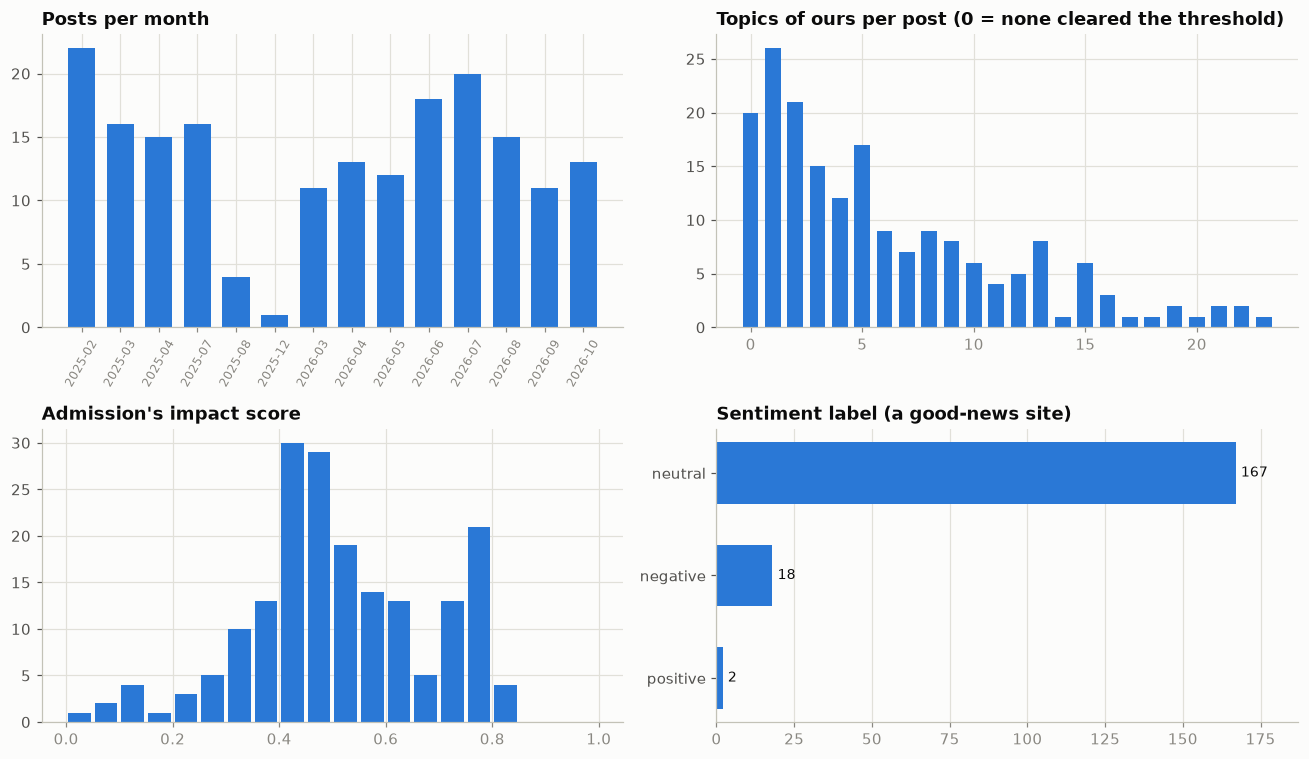

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

per_month = articles["published"].dt.strftime("%Y-%m").value_counts().sort_index()
axes[0, 0].bar(per_month.index, per_month.values, color=BLUE, width=0.7)
axes[0, 0].set_title("Posts per month")
axes[0, 0].tick_params(axis="x", rotation=60, labelsize=8)

topics_per_post = topics_long.groupby("url").size().reindex(articles.index, fill_value=0)
counts = topics_per_post.value_counts().sort_index()
axes[0, 1].bar(counts.index, counts.values, color=BLUE, width=0.7)
axes[0, 1].set_title("Topics of ours per post (0 = none cleared the threshold)")

axes[1, 0].hist(articles["impact_score"], bins=np.arange(0, 1.01, 0.05), color=BLUE, rwidth=0.85)
axes[1, 0].set_title("Admission's impact score")

sent = articles["sentiment"].value_counts()
hbar(axes[1, 1], list(sent.index), list(sent.values), "Sentiment label (a good-news site)")
fig.tight_layout()

In [7]:
first = topics_long[topics_long["rank"] == 1].set_index("url")["confidence"]
second = topics_long[topics_long["rank"] == 2].set_index("url")["confidence"]
gap = (first - second).dropna()

distributions = pd.DataFrame({
    "entities per post": entities_long.groupby("url").size().reindex(articles.index, fill_value=0),
    "proper names per post": entities_long[entities_long["proper"]].groupby("url")["key"].nunique().reindex(articles.index, fill_value=0),
    "claims per post": claims_long.groupby("url").size().reindex(articles.index, fill_value=0),
    "topics per post": topics_per_post,
    "words per post": articles["words"],
}).describe(percentiles=[0.1, 0.5, 0.9]).T.round(1)

print(f"Top topic's confidence: median {first.median():.3f} (min {first.min():.3f}, max {first.max():.3f}).")
print(f"Gap between the first and second topic: median {gap.median():.3f}; under 0.02 in {(gap < 0.02).sum()} of {len(gap)} posts with two or more.")
distributions

Top topic's confidence: median 0.417 (min 0.351, max 0.580).
Gap between the first and second topic: median 0.020; under 0.02 in 70 of 141 posts with two or more.


,count,mean,std,min,10%,50%,90%,max
entities per post,187.0,16.1,8.9,2.0,7.0,14.0,28.0,50.0
proper names per post,187.0,14.0,8.4,1.0,6.0,12.0,27.0,43.0
claims per post,187.0,9.5,4.8,1.0,4.0,9.0,16.0,31.0
topics per post,187.0,6.0,5.5,0.0,0.0,4.0,14.4,23.0
words per post,187.0,772.8,291.5,383.0,522.0,719.0,1075.0,2250.0


**Reading it:** every field is filled except our topics (20 posts get none) and tags (61 posts have none). The
classifier's confidences are compressed: the top topic barely clears the next, so a post carries anywhere from 0 to all
23 topics depending on how flat its scores are. And 167 of 187 posts on a good-news site read as *neutral*: sentiment
measures tone, not the good the story reports. That is what the impact score is for.

In [8]:
distinct = entities_long.drop_duplicates("key").set_index("key")
posts_of = entities_long.groupby("key")["url"].nunique()

types_of_text = distinct.groupby(distinct["name"].map(fold))["type"].nunique()
spellings = distinct.groupby([distinct["type"], distinct["name"].map(fold)])["name"].nunique()

def examples(mask, n=8):
    keys = posts_of[mask[mask].index].sort_values(ascending=False).index[:n]
    return ", ".join(f"{distinct.loc[k, 'name']} ({distinct.loc[k, 'type']}, {posts_of[k]})" for k in keys)

common = ~distinct["name"].map(lambda s: any(ch.isupper() for ch in s))
two_chars = distinct["name"].str.strip().str.len() == 2
long_span = distinct["name"].str.split().str.len() >= 5
credits = distinct["name"].map(fold).isin(SELF_AND_CREDITS)

noise = pd.DataFrame([
    ["common nouns (no capital letter)", common.sum(), examples(common)],
    ["two characters", two_chars.sum(), examples(two_chars, 12)],
    ["five words or more", long_span.sum(), examples(long_span, 5)],
    ["the site itself, the sources heading", credits.sum(), examples(credits)],
    ["one name under several types", (types_of_text > 1).sum(),
     ", ".join(types_of_text[types_of_text > 1].sort_values(ascending=False).index[:6])],
    ["one name, several spellings", (spellings > 1).sum(),
     "; ".join(" / ".join(sorted(distinct[(distinct["type"] == t) & (distinct["name"].map(fold) == f)]["name"]))
               for t, f in spellings[spellings > 1].index[:5])],
], columns=["issue", "distinct entities", "examples (posts)"])
print(f"{len(distinct)} distinct entities; {distinct['name'].map(proper_name).sum()} read as names; "
      f"{entities_long.loc[entities_long['proper'], 'key'].nunique()} kept for the analysis.")
noise

2383 distinct entities; 2065 read as names; 2063 kept for the analysis.


,issue,distinct entities,examples (posts)
0,common nouns (no capital letter),318,"investigadores (person, 8), gobierno (organiza..."
1,two characters,8,"UE (country, 4), UE (organization, 3), UK (cou..."
2,five words or more,97,Organización Mundial de la Salud (organization...
3,"the site itself, the sources heading",2,"Inspiring News (organization, 8), Fuentes (per..."
4,one name under several types,110,"corea del sur, bardibas, family time, florida,..."
5,"one name, several spellings",3,Amsterdam / Ámsterdam; Mexico / México; Oscar ...


In [9]:
# Admission was asked and recorded, and decided nothing: every post is kept here.
admission = articles.groupby("section", observed=True).agg(
    posts=("admitted", "size"),
    admitted=("admitted", "sum"),
    topic_not_relevant=("rejected_for", lambda s: sum("topic_not_relevant" in r for r in s)),
    not_positive_impact=("rejected_for", lambda s: sum("not_positive_impact" in r for r in s)),
)
admission

,posts,admitted,topic_not_relevant,not_positive_impact
section,,,,
Ciencia,23,23,0,0
Tecnología,11,10,0,1
Salud,22,20,1,1
Medio ambiente,35,33,0,2
Sociedad,36,24,11,5
Cultura,42,31,8,7
Buenas de la semana,14,14,0,0
Sin categoría,4,4,0,0


## 3. The dump's own topics: WordPress categories and tags

The site's own labelling, before any of ours.

29 posts carry more than one category; the commonest pairs: [('Cultura + Sociedad', 9), ('Medio ambiente + Sociedad', 3), ('Ciencia + Cultura', 2), ('Ciencia + Salud', 2), ('Ciencia + Sociedad', 2)]


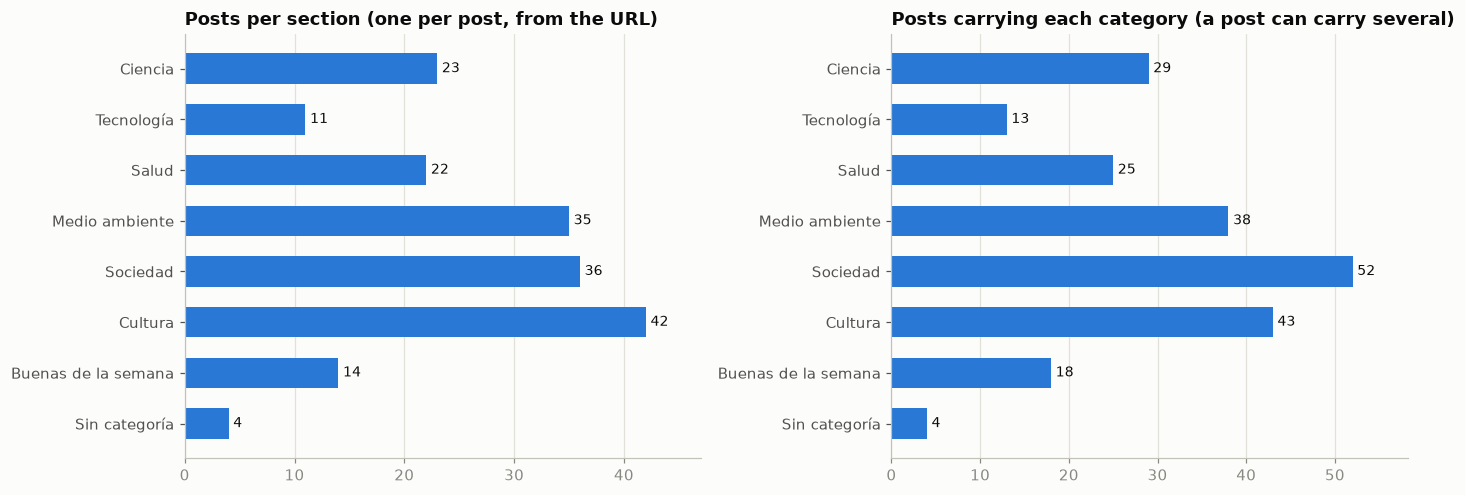

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

section_counts = articles["section"].value_counts().reindex(SECTIONS)
hbar(axes[0], SECTIONS, list(section_counts.values), "Posts per section (one per post, from the URL)")

category_counts = pd.Series(Counter(c for cs in articles["categories"] for c in cs)).reindex(SECTIONS).fillna(0).astype(int)
hbar(axes[1], SECTIONS, list(category_counts.values), "Posts carrying each category (a post can carry several)")
fig.tight_layout()

multi = articles[articles["categories"].map(len) > 1]
print(f"{len(multi)} posts carry more than one category; the commonest pairs:",
      Counter(" + ".join(sorted(c)) for c in multi["categories"]).most_common(5))

126 posts have tags; 119 of the 169 tags are used once.


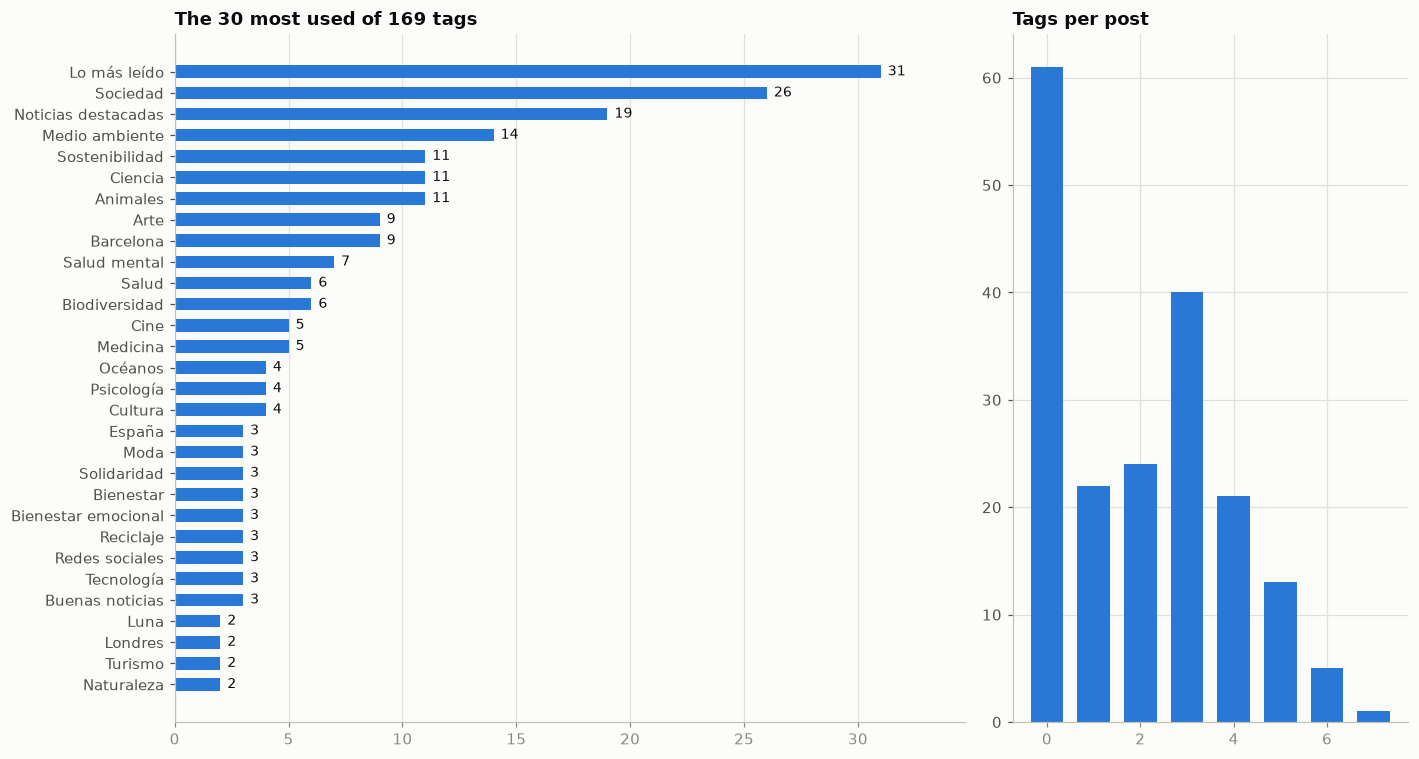

In [11]:
tag_counts = pd.Series(Counter(t for ts in articles["tags"] for t in ts)).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [2, 1]})
top_tags = tag_counts.head(30)
hbar(axes[0], list(top_tags.index), list(top_tags.values), f"The 30 most used of {len(tag_counts)} tags")
tags_per_post = articles["tags"].map(len).value_counts().sort_index()
axes[1].bar(tags_per_post.index, tags_per_post.values, color=BLUE, width=0.7)
axes[1].set_title("Tags per post")
fig.tight_layout()
print(f"{(articles['tags'].map(len) > 0).sum()} posts have tags; {(tag_counts == 1).sum()} of the {len(tag_counts)} tags are used once.")

In [12]:
# Which tags each section uses: the five most used per section.
tag_rows = articles[["section", "tags"]].explode("tags").dropna()
pd.DataFrame({
    section: [f"{t} ({n})" for t, n in Counter(tag_rows.loc[tag_rows["section"] == section, "tags"]).most_common(5)]
    + [""] * (5 - len(Counter(tag_rows.loc[tag_rows["section"] == section, "tags"]).most_common(5)))
    for section in SECTIONS
}, index=[f"#{i}" for i in range(1, 6)]).T

,#1,#2,#3,#4,#5
Ciencia,Ciencia (4),Psicología (2),Salud mental (2),Luna (2),Lo más leído (1)
Tecnología,Lo más leído (2),Inteligencia Artificial (2),Ciencia (1),Futuro (1),IA (1)
Salud,Lo más leído (5),Salud mental (4),Bienestar (2),Bienestar emocional (2),Medicina (2)
Medio ambiente,Noticias destacadas (7),Medio ambiente (7),Lo más leído (5),Biodiversidad (4),Animales (4)
Sociedad,Sociedad (7),Lo más leído (5),Noticias destacadas (5),Arte (3),Turismo (2)
Cultura,Lo más leído (9),Sociedad (9),Barcelona (5),Arte (4),Cine (3)
Buenas de la semana,Sostenibilidad (5),Animales (5),Ciencia (5),Medio ambiente (5),Sociedad (4)
Sin categoría,Lo más leído (2),Cine (1),Cultura (1),Noticias destacadas (1),Ciencia (1)


**Reading it:** the tags are editorial as much as topical. The most used is *Lo más leído* (most read), then
*Sociedad* and *Noticias destacadas*. Most tags are used once, and place names (*Barcelona*, *España*, *Londres*)
are mixed in with subjects. So a tag says something about a post's subject only after the editorial and place tags are
set aside, which the mapping below does.

## 4. Our labels, with the WordPress ones taken into account

Three sources of our topics for each post:

1. **The classifier:** the topics in the graph (`ABOUT`), main topic first.
2. **The tags:** each tag that names a subject maps to one of our 23 topics (`TAG_TO_TOPIC`). Editorial tags, places
   and ambiguous tags map to nothing, and are listed below so you can see what was left out.
3. **The category:** each category maps to one of our five groups (`CATEGORY_TO_GROUP`). Its fallback topic is the one
   most often first among that category's posts in the same group, which is decided by the data, not by hand.

A post's **WordPress topics** are its tags' topics, else its category's fallback topic. A post the classifier left
without a topic takes its WordPress topic as its **closest topic**, so every post has one. The mapping is a reading of
the site's labels, not a model: edit it and re-run.

In [13]:
TAG_TO_TOPIC = {
    # society
    "Sociedad": "community", "Comunidad": "community", "Solidaridad": "community", "Innovación social": "community",
    "Activismo": "community", "Voluntario": "community", "Voluntarios": "community", "Mujeres": "community",
    "Sororidad": "community", "Personas mayores": "community", "Bomberos": "community",
    "Barrios": "cities", "Vivienda social": "cities",
    "Emprendimiento": "employment", "Productividad": "employment",
    "Talleres": "education", "Tutoriales": "education",
    # science
    "Ciencia": "research", "Investigación": "research", "Estudio": "research", "Ciencia ciudadana": "research",
    "Premios Nobel": "research", "Geología": "research", "Fósiles": "research",
    "Tecnología": "technology", "Inteligencia Artificial": "technology", "IA": "technology",
    "Innovación": "technology", "Innovacion": "technology", "Móvil": "technology",
    "Luna": "space", "NASA": "space", "Artemis": "space", "Astronomia": "space", "Astrounautas": "space",
    "Espacio": "space", "Exploración espacial": "space",
    # environment
    "Medio ambiente": "sustainability", "Sostenibilidad": "sustainability", "Reciclaje": "sustainability",
    "Basura": "sustainability", "Vertedero": "sustainability", "Moda sostenible": "sustainability", "Agua": "sustainability",
    "Animales": "nature", "Biodiversidad": "nature", "Océanos": "nature", "Conservación marina": "nature",
    "Ecosistema": "nature", "Naturaleza": "nature", "Conservación": "nature", "Flores": "nature", "Parques": "nature",
    "iNaturalist": "nature", "David Attenborough": "nature", "Planeta Tierra": "nature",
    "Emisiones CO2": "climate", "Combustibles fósiles": "energy", "Batería": "energy", "Carne": "food",
    # culture
    "Arte": "arts", "Cultura": "arts", "Moda": "arts", "Diseño": "arts", "Arquitectura": "arts", "Le Corbusier": "arts",
    "perriand": "arts", "Cerámica": "arts", "Artistas": "arts", "Exposición": "arts", "Baile": "arts", "Música": "arts",
    "Cine": "entertainment", "Disney": "entertainment", "Pixar": "entertainment", "Hannah Montana": "entertainment",
    "Televisión": "entertainment", "Olivia Rodrigo": "entertainment", "memes": "entertainment",
    "Libros": "literature", "Literatura": "literature", "Poesía": "literature", "Jane Austen": "literature",
    "Sant Jordi": "literature", "Ciencia ficción": "literature", "Project Hail Mary": "literature",
    "Museo": "heritage", "Historia": "heritage", "Tradición": "heritage", "Fiestas populares": "heritage",
    "Mitología": "heritage", "Gaudí": "heritage",
    "Superación": "inspiration", "Reto": "inspiration", "Buenas noticias": "inspiration",
    # health
    "Medicina": "medicine", "Cáncer infantil": "medicine", "ELA": "medicine", "Enfermedades": "medicine",
    "Hospital": "medicine", "Hospital del Mar": "medicine", "Humanizacion UCI": "medicine", "Transplantes": "medicine",
    "Piel de mariposa": "medicine",
    "Salud mental": "mental_health", "Psicología": "mental_health", "Bienestar": "mental_health",
    "Bienestar emocional": "mental_health", "Ansiedad": "mental_health", "Mindfulness": "mental_health",
    "Soledad": "mental_health", "Doomscrolling": "mental_health", "JOMO": "mental_health",
    "Salud intestinal": "nutrition", "Microbioma": "nutrition", "Nutrición": "nutrition", "Alimentación": "nutrition",
    "Deporte": "fitness", "Deportes": "fitness", "Maratón": "fitness", "Hábitos saludables": "fitness",
    "Salud": "public_health", "Sanidad": "public_health",
}

CATEGORY_TO_GROUP = {"Ciencia": "science", "Tecnología": "science", "Salud": "health", "Medio ambiente": "environment",
                     "Sociedad": "society", "Cultura": "culture", "Buenas de la semana": None, "Sin categoría": None}

assert set(TAG_TO_TOPIC.values()) <= set(TOPIC_NAME), set(TAG_TO_TOPIC.values()) - set(TOPIC_NAME)

unmapped = tag_counts[~tag_counts.index.isin(TAG_TO_TOPIC)]
print(f"{tag_counts.index.isin(TAG_TO_TOPIC).sum()} of {len(tag_counts)} tags map to a topic, "
      f"covering {tag_counts[tag_counts.index.isin(TAG_TO_TOPIC)].sum()} of {tag_counts.sum()} tag uses.")
print("Not mapped (editorial, places, ambiguous):", ", ".join(f"{t} ({n})" for t, n in unmapped.items()))

123 of 169 tags map to a topic, covering 263 of 376 tag uses.
Not mapped (editorial, places, ambiguous): Lo más leído (31), Noticias destacadas (19), Barcelona (9), España (3), Redes sociales (3), Londres (2), Turismo (2), Noticias (2), Hábitos (2), Mundial 2026 (2), 2026 (2), Jóvenes (2), Nostalgia (1), Japón (1), Himalaya (1), Everest (1), Comunicación (1), Chile (1), Futuro (1), Hawái (1), Cataluña (1), Ámsterdam (1), Publicidad (1), Ropa (1), Adopción (1), Africa (1), Niños (1), Finlandia (1), Unión Europea (1), Colombia (1), FIFA (1), EEUU (1), Siesta nórdica (1), Países nórdicos (1), Bebés (1), Ética (1), Erin Brockovich (1), Generación Z (1), Periodismo (1), Tierra (1), Vida (1), Premios Princesa de Girona (1), América Latina (1), Berlín (1), Viajar (1), Francia (1)


In [14]:
main_topic = topics_long[topics_long["rank"] == 1].set_index("url")["topic"]
classifier_topics = topics_long.sort_values("rank").groupby("url")["topic"].agg(list)

# Each category's fallback topic: the topic most often first among its posts, within the category's group.
fallback = {}
for category, group in CATEGORY_TO_GROUP.items():
    if group is None:
        continue
    in_category = articles.index[articles["categories"].map(lambda cs: category in cs)]
    firsts = main_topic.reindex(in_category).dropna()
    firsts = firsts[firsts.map(GROUP_OF) == group]
    fallback[category] = firsts.value_counts().idxmax() if len(firsts) else TOPIC_GROUPS[group][0]

def wordpress_topics(post) -> list[str]:
    from_tags = [TAG_TO_TOPIC[t] for t in post["tags"] if t in TAG_TO_TOPIC]
    if from_tags:
        # most named first; ties in tag order
        return [t for t, _ in Counter(from_tags).most_common()]
    return list(dict.fromkeys(fallback[c] for c in post["categories"] if c in fallback))

articles["topics_classifier"] = classifier_topics.reindex(articles.index).map(lambda v: v if isinstance(v, list) else [])
articles["topics_wordpress"] = articles.apply(wordpress_topics, axis=1)
articles["wordpress_from"] = articles.apply(lambda p: "tags" if any(t in TAG_TO_TOPIC for t in p["tags"]) else ("category" if p["topics_wordpress"] else "none"), axis=1)
articles["main_topic"] = main_topic.reindex(articles.index)
articles["closest_topic"] = articles["main_topic"].fillna(articles["topics_wordpress"].map(lambda v: v[0] if v else None))
articles["topic_from"] = np.where(articles["main_topic"].notna(), "classifier",
                                  np.where(articles["closest_topic"].notna(), "WordPress", "none"))
articles["group"] = articles["closest_topic"].map(GROUP_OF)

print("Category fallback topics:", {c: TOPIC_NAME[t] for c, t in fallback.items()})
print("Where each post's topic comes from:", articles["topic_from"].value_counts().to_dict())
print("Where its WordPress topics come from:", articles["wordpress_from"].value_counts().to_dict())
print("The posts with no classifier topic took theirs from:",
      articles.loc[articles["topic_from"] == "WordPress", "wordpress_from"].value_counts().to_dict())
articles.loc[articles["topic_from"] == "WordPress", ["section", "tags", "topics_wordpress", "closest_topic"]].head(20)

Category fallback topics: {'Ciencia': 'Biology', 'Tecnología': 'Technology', 'Salud': 'Medicine', 'Medio ambiente': 'Nature & Biodiversity', 'Sociedad': 'Community & Social Impact', 'Cultura': 'Entertainment'}
Where each post's topic comes from: {'classifier': 167, 'WordPress': 20}
Where its WordPress topics come from: {'tags': 103, 'category': 80, 'none': 4}
The posts with no classifier topic took theirs from: {'category': 12, 'tags': 8}


,section,tags,topics_wordpress,closest_topic
url,,,,
https://inspiringnews.ai/cultura/la-iglesia-barroca-de-sant-sever-reabre-sus-puertas-tras-una-restauracion-ejemplar/,Cultura,[Lo más leído],[entertainment],entertainment
https://inspiringnews.ai/cultura/barcelona-se-rinde-ante-botero-la-mayor-exposicion-del-artista-colombiano-llega-al-palau-martorell/,Cultura,[Lo más leído],[entertainment],entertainment
https://inspiringnews.ai/sociedad/un-hallazgo-inesperado-en-via-laietana/,Sociedad,[Lo más leído],[community],community
https://inspiringnews.ai/cultura/descubre-la-deslumbrante-alfombra-floral-de-70-m%c2%b2-en-barcelona-una-exposicion-gratuita/,Cultura,[],[entertainment],entertainment
https://inspiringnews.ai/sociedad/la-emotiva-historia-de-hachiko-el-perro-que-nunca-olvido/,Sociedad,[Lo más leído],[community],community
https://inspiringnews.ai/sociedad/melanie-barratt-la-primera-mujer-ciega-en-cruzar-el-canal-de-la-mancha-a-nado/,Sociedad,[],[community],community
https://inspiringnews.ai/sociedad/heroico-perro-rocky-salva-63-vidas-durante-deslizamiento-en-himachal/,Sociedad,[],[community],community
https://inspiringnews.ai/sociedad/un-pequeno-perro-se-convierte-en-heroe-al-salvar-a-excursionista-atrapado-en-glaciar-suizo/,Sociedad,[],[community],community
https://inspiringnews.ai/cultura/un-fan-de-pokemon-logra-que-el-papa-firme-su-carta-de-popplio/,Cultura,[],[entertainment],entertainment


In [15]:
# Do the classifier and WordPress agree? Only posts with both.
both = articles[(articles["main_topic"].notna()) & (articles["topics_wordpress"].map(len) > 0)]
agree = pd.DataFrame({
    "posts": both.groupby("section", observed=True).size(),
    "main topic among WordPress topics": both.groupby("section", observed=True).apply(
        lambda d: sum(m in w for m, w in zip(d["main_topic"], d["topics_wordpress"]))),
    "same group": both.groupby("section", observed=True).apply(
        lambda d: sum(GROUP_OF[m] in {GROUP_OF[t] for t in w} for m, w in zip(d["main_topic"], d["topics_wordpress"]))),
})
agree.loc["all"] = agree.sum()
agree["same group, share"] = (agree["same group"] / agree["posts"]).map("{:.0%}".format)
agree

,posts,main topic among WordPress topics,same group,"same group, share"
section,,,,
Ciencia,23,10,11,48%
Tecnología,11,4,6,55%
Salud,21,13,17,81%
Medio ambiente,35,17,31,89%
Sociedad,25,11,15,60%
Cultura,34,14,19,56%
Buenas de la semana,11,4,7,64%
Sin categoría,3,2,3,100%
all,163,75,109,67%


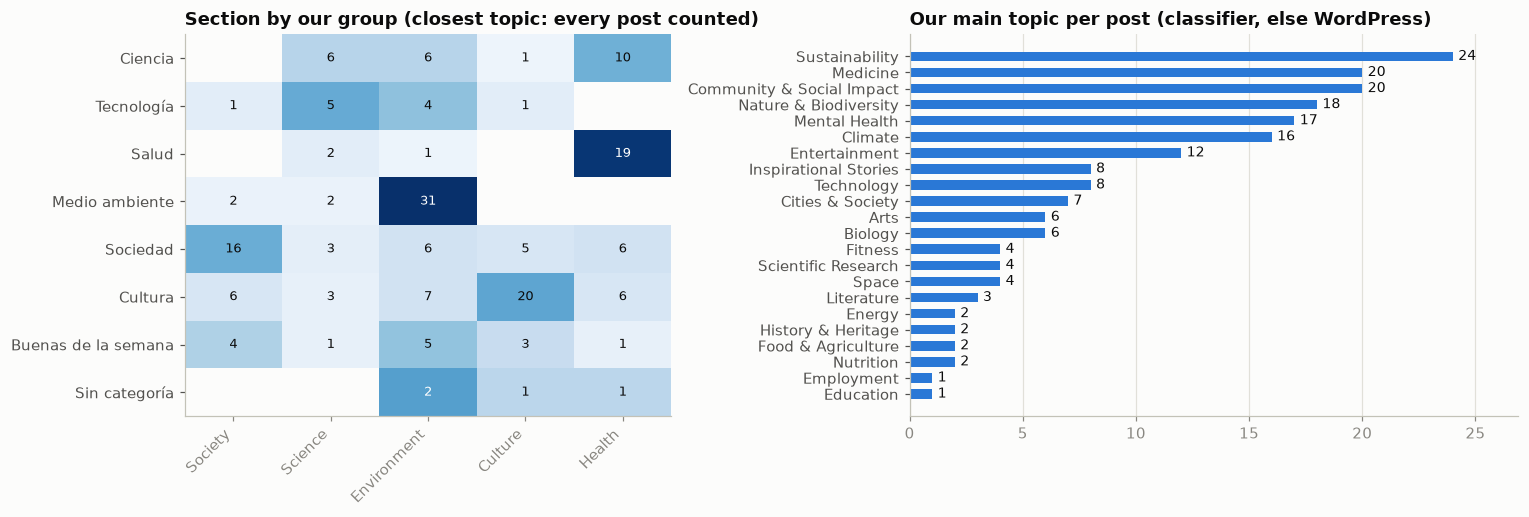

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})

by_group = pd.crosstab(articles["section"], articles["group"].map(TOPIC_GROUP_NAMES)).reindex(
    index=SECTIONS, columns=[TOPIC_GROUP_NAMES[g] for g in GROUPS], fill_value=0)
heat(axes[0], by_group, "Section by our group (closest topic: every post counted)",
     colour_by=by_group.div(by_group.sum(axis=1), axis=0))

final_counts = articles["closest_topic"].map(TOPIC_NAME).value_counts()
colors = [BLUE] * len(final_counts)
hbar(axes[1], list(final_counts.index), list(final_counts.values), "Our main topic per post (classifier, else WordPress)")
fig.tight_layout()

In [17]:
# Every topic label a post carries, ours and WordPress's together, by section: what the map's "topics" and labels show.
label_rows = pd.concat([
    articles[["section", "topics_classifier"]].explode("topics_classifier").rename(columns={"topics_classifier": "topic"}).assign(source="classifier"),
    articles[["section", "topics_wordpress"]].explode("topics_wordpress").rename(columns={"topics_wordpress": "topic"}).assign(source="WordPress"),
]).dropna()
labels_table = pd.crosstab(label_rows["topic"].map(TOPIC_NAME), [label_rows["source"]]).sort_values("classifier", ascending=False)
labels_table["WordPress, share of posts"] = (labels_table["WordPress"] / len(articles)).map("{:.0%}".format)
labels_table

source,WordPress,classifier,"WordPress, share of posts"
topic,,,
Sustainability,25,108,13%
Climate,1,87,1%
Scientific Research,15,67,8%
Nature & Biodiversity,42,62,22%
Community & Social Impact,53,61,28%
Food & Agriculture,1,60,1%
Technology,16,60,9%
Cities & Society,2,58,1%
Medicine,21,56,11%


**Reading it:** where both exist, the classifier's main topic is in the same group as the WordPress labels for 109
of 163 posts (67%). It agrees most in *Medio ambiente* (89%) and *Salud* (81%), and least in *Ciencia* (48%), whose
research is often medical. Each of the 20 posts the classifier left without a topic gets one: 8 from their tags, 12 from their
category.

## 5. Claims per article

The claim extractor's sentences, as the graph holds them (`CONTAINS_CLAIM`): its check-worthiness `confidence`
(0.5, the floor for being a claim at all, up to 1.0) and its `opinion_score`. None was selected or checked
(`verify=false`). Per post: how many claims there are, how dense they are in the text, how check-worthy they are, how
many carry an opinion marker, a figure or a name.

In [18]:
NUMBER = re.compile(r"\d")
names_by_url = entities_long[entities_long["proper"]].groupby("url")["name"].agg(lambda s: sorted({fold(n) for n in s}, key=len, reverse=True))

claims_long["words"] = claims_long["text"].str.split().str.len()
claims_long["has_figure"] = claims_long["text"].str.contains(NUMBER)
# The opinion score is 0 or 0.33 here (one opinion marker of three): a sentence over the extractor's opinion
# ceiling was never kept as a claim. So "with an opinion marker" is any score above 0.
claims_long["opinion_marker"] = claims_long["opinion_score"] > 0

# A name counts when it appears in the claim as whole words ("UE" must not match inside "puede").
patterns = {u: [re.compile(r"(?<!\w)" + re.escape(n) + r"(?!\w)") for n in ns] for u, ns in names_by_url.items()}
claims_long["names"] = [sum(1 for rx in patterns.get(u, []) if rx.search(fold(t))) for u, t in zip(claims_long["url"], claims_long["text"])]

claims_per_article = claims_long.groupby("url").agg(
    claims=("claim_id", "size"),
    confidence_mean=("confidence", "mean"),
    confidence_max=("confidence", "max"),
    opinion_mean=("opinion_score", "mean"),
    opinion_markers=("opinion_marker", "sum"),
    with_figure=("has_figure", "sum"),
    naming_someone=("names", lambda s: int((s > 0).sum())),
    words_mean=("words", "mean"),
    selected=("selected", "sum"),
).reindex(articles.index)
claims_per_article.insert(0, "title", articles["title"])
claims_per_article.insert(1, "section", articles["section"])
claims_per_article.insert(3, "per_100_words", (claims_per_article["claims"] / articles["words"] * 100).round(2))
claims_per_article = claims_per_article.round(3)

print(f"{len(claims_long)} claims in {len(claims_per_article)} posts; selected for checking: {int(claims_per_article['selected'].sum())}.")
print("Opinion scores:", claims_long["opinion_score"].round(2).value_counts().sort_index().to_dict(),
      "| check-worthiness from", claims_long["confidence"].min(), "to", claims_long["confidence"].max())
claims_per_article.drop(columns="selected").describe(percentiles=[0.1, 0.5, 0.9]).T.round(2)

1782 claims in 187 posts; selected for checking: 0.
Opinion scores: {0.0: 1349, 0.33: 433} | check-worthiness from 0.5 to 1.0


,count,mean,std,min,10%,50%,90%,max
claims,187.0,9.53,4.76,1.00,4.00,9.00,16.00,31.00
per_100_words,187.0,1.28,0.57,0.13,0.65,1.23,2.07,2.87
confidence_mean,187.0,0.60,0.06,0.50,0.52,0.59,0.67,0.83
confidence_max,187.0,0.77,0.12,0.50,0.60,0.80,0.95,1.00
opinion_mean,187.0,0.08,0.06,0.00,0.00,0.08,0.16,0.33
opinion_markers,187.0,2.32,1.78,0.00,0.00,2.00,4.40,9.00
with_figure,187.0,6.02,4.02,0.00,1.00,5.00,12.00,20.00
naming_someone,187.0,6.56,4.10,0.00,2.00,6.00,12.00,26.00
words_mean,187.0,26.94,5.07,14.00,20.89,26.62,34.00,45.50


In [19]:
claims_by_section = claims_per_article.groupby("section", observed=True).agg(
    posts=("claims", "size"), claims=("claims", "sum"), median_claims=("claims", "median"),
    per_100_words=("per_100_words", "median"), confidence=("confidence_mean", "mean"),
    opinion_markers=("opinion_markers", "sum"), with_figure=("with_figure", "sum"))
claims_by_section["opinion_markers"] = (claims_by_section["opinion_markers"] / claims_by_section["claims"]).map("{:.0%}".format)
claims_by_section["with_figure"] = (claims_by_section["with_figure"] / claims_by_section["claims"]).map("{:.0%}".format)
claims_by_section.round(3)

,posts,claims,median_claims,per_100_words,confidence,opinion_markers,with_figure
section,,,,,,,
Ciencia,23,199,8.0,0.990,0.583,30%,55%
Tecnología,11,63,5.0,0.860,0.552,43%,49%
Salud,22,168,7.0,1.025,0.593,26%,60%
Medio ambiente,35,356,10.0,1.390,0.598,20%,65%
Sociedad,36,361,9.5,1.345,0.617,27%,63%
Cultura,42,368,9.0,1.200,0.598,18%,70%
Buenas de la semana,14,223,16.5,1.330,0.617,24%,64%
Sin categoría,4,44,10.5,1.105,0.580,30%,64%


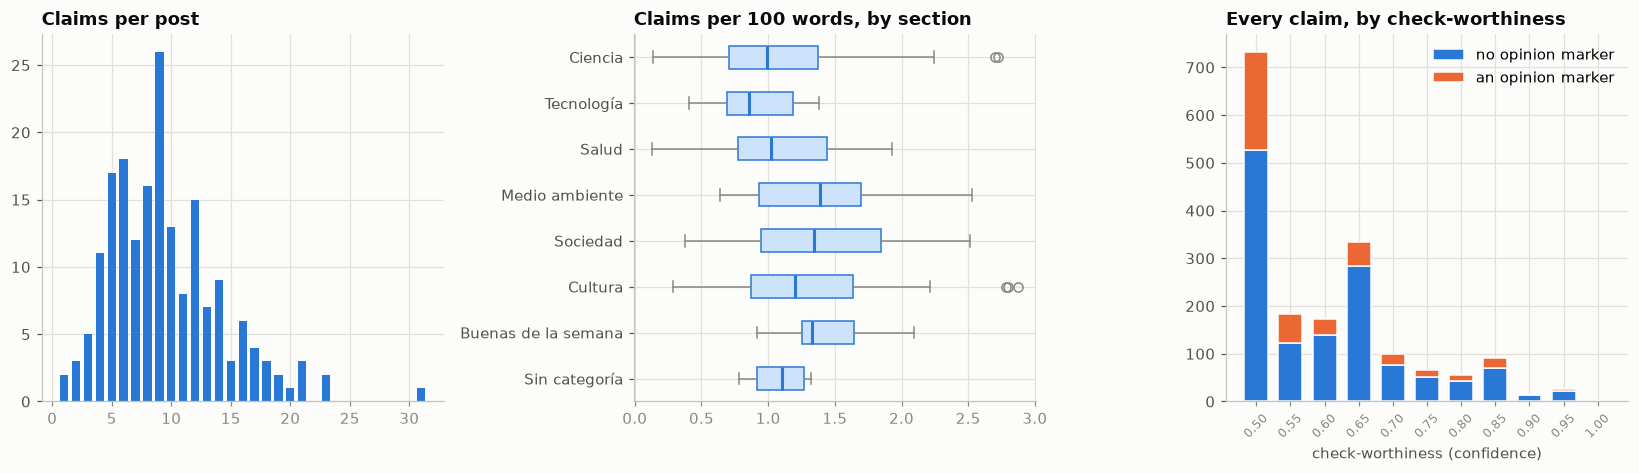

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

counts = claims_per_article["claims"].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=BLUE, width=0.7)
axes[0].set_title("Claims per post")

order = [s for s in SECTIONS if (claims_per_article["section"] == s).any()]
data = [claims_per_article.loc[claims_per_article["section"] == s, "per_100_words"].dropna() for s in order]
axes[1].boxplot(data, orientation="horizontal", tick_labels=order, widths=0.5, patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=BLUE, linewidth=2),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED), flierprops=dict(markeredgecolor=MUTED))
axes[1].invert_yaxis()
axes[1].set_title("Claims per 100 words, by section")

levels = sorted(claims_long["confidence"].round(2).unique())
plain = claims_long[~claims_long["opinion_marker"]]["confidence"].round(2).value_counts().reindex(levels, fill_value=0)
marked = claims_long[claims_long["opinion_marker"]]["confidence"].round(2).value_counts().reindex(levels, fill_value=0)
x = np.arange(len(levels))
axes[2].bar(x, plain.values, width=0.7, color=SLOTS[0], label="no opinion marker", edgecolor="#fcfcfb", linewidth=1)
axes[2].bar(x, marked.values, width=0.7, bottom=plain.values, color=SLOTS[1], label="an opinion marker", edgecolor="#fcfcfb", linewidth=1)
axes[2].set_xticks(x, [f"{v:.2f}" for v in levels], rotation=45, fontsize=8)
axes[2].set_xlabel("check-worthiness (confidence)")
axes[2].legend(frameon=False)
axes[2].set_title("Every claim, by check-worthiness")
fig.tight_layout()

In [21]:
# The full table, one row per post (also written to data/claims_per_article.csv in section 8).
claims_per_article.drop(columns="selected").sort_values("claims", ascending=False)

,title,section,claims,per_100_words,confidence_mean,confidence_max,opinion_mean,opinion_markers,with_figure,naming_someone,words_mean
url,,,,,,,,,,,
https://inspiringnews.ai/buenas-de-la-semana/las-5-buenas-noticias-del-19-de-octubre-al-23-de-octubre/,De un fármaco contra la hepatitis B al regreso...,Buenas de la semana,31,1.78,0.637,0.95,0.085,8,20,26,37.194
https://inspiringnews.ai/sociedad/rescate-inspirador-madre-e-hijo-perdidos-en-el-bosque-de-california/,Rescate Inspirador: Madre e Hijo Perdidos en e...,Sociedad,23,1.83,0.554,0.85,0.057,4,9,21,21.478
https://inspiringnews.ai/buenas-de-la-semana/buenas-noticias-de-la-semana-del-28-de-septiembre-al-02-de-octubre/,De un hallazgo científico en un motel a una re...,Buenas de la semana,23,1.88,0.609,0.85,0.115,8,13,17,40.130
https://inspiringnews.ai/cultura/lo-que-tus-artistas-favoritos-hacen-por-el-mundo/,"Shakira, Bad Bunny, Karol G y más: lo que tus ...",Cultura,21,2.11,0.593,0.85,0.094,6,16,15,22.000
https://inspiringnews.ai/buenas-de-la-semana/buenas-noticias-de-la-semana/,Cinco historias que demuestran que sí estamos ...,Buenas de la semana,21,1.41,0.595,0.70,0.047,3,14,11,28.810
...,...,...,...,...,...,...,...,...,...,...,...
https://inspiringnews.ai/tecnologia/un-robot-revolucionario-desmonta-desechos-electronicos-para-un-futuro-sostenible/,Un robot revolucionario desmonta desechos elec...,Tecnología,2,0.41,0.550,0.60,0.165,1,1,2,34.000
https://inspiringnews.ai/sociedad/barcelona-mas-alla-del-turismo-design-place/,Barcelona más allá del turismo: los espacios q...,Sociedad,2,0.40,0.625,0.75,0.000,0,2,2,17.000
https://inspiringnews.ai/cultura/hay-una-razon-por-la-que-respondes-con-memes-la-psicologia-lo-explica/,Hay una razón por la que respondes con memes: ...,Cultura,2,0.29,0.500,0.50,0.165,1,0,1,34.500


In [22]:
# The most check-worthy claims of the import: what a fact-check would start with.
claims_long.sort_values("confidence", ascending=False)[["section", "confidence", "opinion_score", "has_figure", "text"]].head(12)

,section,confidence,opinion_score,has_figure,text
1768,Cultura,1.00,0.00,True,"Y, según anunció ella en junio, el 100 % de la..."
776,Medio ambiente,1.00,0.00,True,"El compromiso global del marco ""30x30"" (proteg..."
1091,Cultura,0.95,0.00,True,"En España, el Barómetro de la Soledad No Desea..."
366,Sociedad,0.95,0.00,True,Este enfoque colaborativo involucró a miles de...
1379,Buenas de la semana,0.95,0.00,True,Un estudio publicado el 29 de julio de 2026 en...
1040,Sociedad,0.95,0.33,True,El hecho de que el Mundial más grande de la hi...
481,Cultura,0.95,0.33,True,"En 2023, se estimaron 36 millones de embarazos..."
1682,Cultura,0.95,0.00,True,Según el último informe de la reconocida ONG W...
1418,Sin categoría,0.95,0.00,True,"El 4 de agosto de 2026, Leonardo DiCaprio y Je..."
1169,Buenas de la semana,0.95,0.00,True,"El 16 de junio de 2026, el Banco Mundial y el ..."


## 6. Entities, and what connects the sections

Proper names only, each counted once per post that names it.

kind,people,organisations,places,products,events
section,,,,,
Ciencia,62,68,77,15,5
Tecnología,23,36,17,12,1
Salud,56,102,81,16,2
Medio ambiente,90,158,235,7,17
Sociedad,116,112,169,11,13
Cultura,191,151,250,22,34
Buenas de la semana,66,146,161,14,7
Sin categoría,25,19,31,5,2


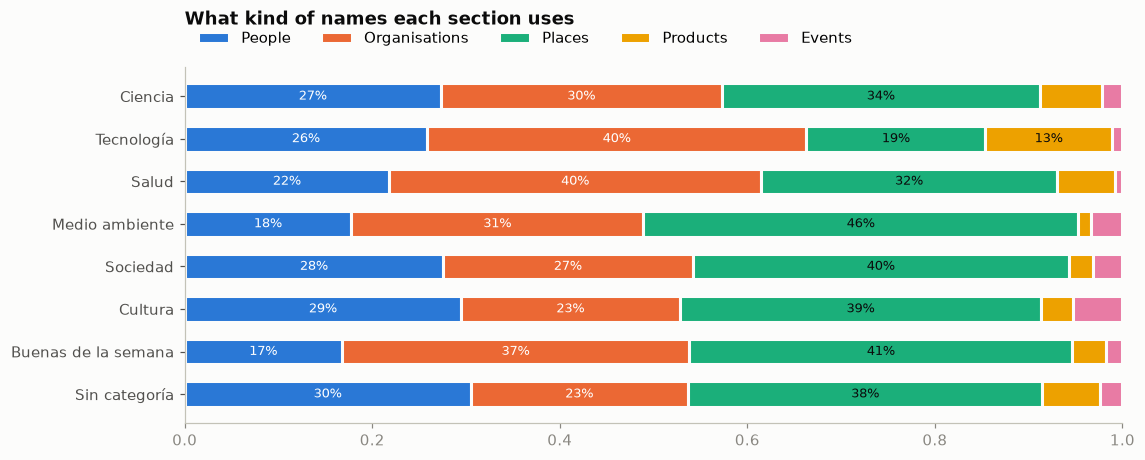

In [23]:
names = entities_long[entities_long["proper"]].drop_duplicates(["url", "key"])

kinds = pd.crosstab(names["section"], names["kind"]).reindex(index=SECTIONS, columns=KINDS, fill_value=0)
shares = kinds.div(kinds.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(11, 4.2))
left = np.zeros(len(shares))
for kind in KINDS:
    ax.barh(SECTIONS, shares[kind], left=left, color=KIND_COLOR[kind], height=0.6, label=kind.capitalize(),
            edgecolor="#fcfcfb", linewidth=2)
    for i, (l, v) in enumerate(zip(left, shares[kind])):
        if v > 0.07:
            ax.text(l + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5,
                    color="white" if kind in ("people", "organisations") else INK)
    left += shares[kind].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.grid(False)
ax.legend(ncol=5, loc="lower left", bbox_to_anchor=(0, 1.02), frameon=False)
ax.set_title("What kind of names each section uses", pad=28)
kinds

In [24]:
posts_by_section = names.groupby(["key", "section"], observed=True)["url"].nunique().unstack(fill_value=0).reindex(columns=SECTIONS, fill_value=0)
name_of = names.groupby("key")["name"].agg(lambda s: s.value_counts().index[0])
kind_of = names.groupby("key")["kind"].first()

top_per_section = pd.DataFrame({
    s: [f"{name_of[k]} ({n})" for k, n in posts_by_section[s][posts_by_section[s] > 0].sort_values(ascending=False).head(8).items()]
    for s in SECTIONS
}).T
top_per_section.columns = [f"#{i + 1}" for i in range(top_per_section.shape[1])]
top_per_section

,#1,#2,#3,#4,#5,#6,#7,#8
Ciencia,Estados Unidos (5),Europa (3),NASA (3),Tierra (2),China (2),España (2),Marte (2),Agencia Espacial Canadiense (2)
Tecnología,NASA (2),Barcelona (1),Las Vegas (1),El Vendrell (1),Tallahassee (1),AiQUOS (1),Apple (1),Miami (1)
Salud,España (6),Estados Unidos (4),Barcelona (3),Reino Unido (3),Sevilla (2),Cataluña (2),India (2),Málaga (2)
Medio ambiente,España (12),Europa (7),Colombia (6),Barcelona (6),Estados Unidos (4),Brasil (4),Alemania (4),India (4)
Sociedad,Barcelona (7),España (5),Estados Unidos (4),India (3),Madrid (3),ONU (3),Países Bajos (2),World Economic Forum (2)
Cultura,Barcelona (16),España (10),Estados Unidos (5),México (5),Canadá (4),Europa (4),Australia (4),Reino Unido (4)
Buenas de la semana,Estados Unidos (6),Francia (4),Reino Unido (3),Japón (3),España (3),Australia (3),Comisión Europea (3),Colombia (3)
Sin categoría,Finlandia (2),BBC (2),Boulder (1),Aktaş (1),Houston (1),Londres (1),Masala (1),Antártida (1)


1906 of 2063 names appear in one section only; 157 in two or more, 58 in three or more.


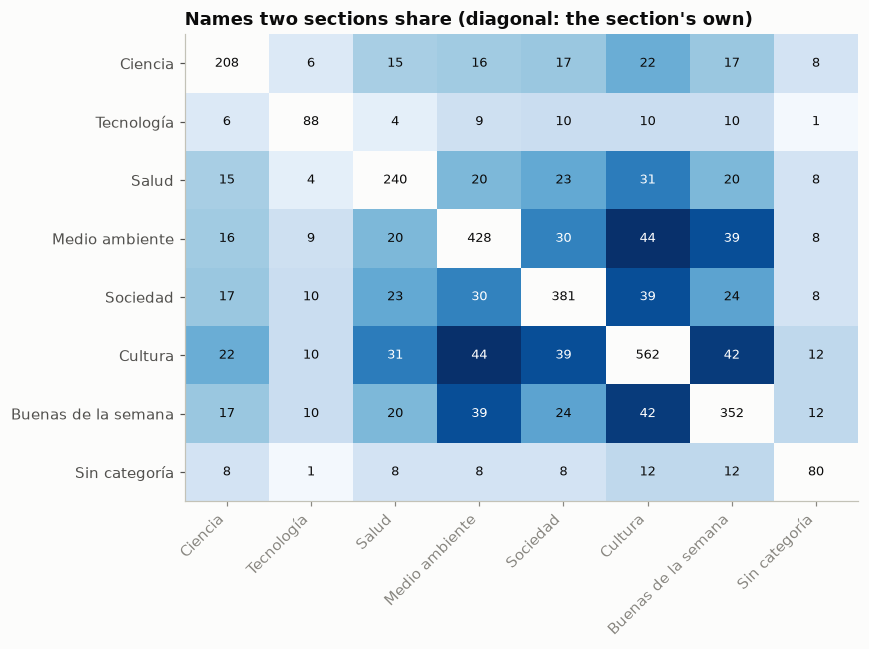

In [25]:
shared = pd.DataFrame(0, index=SECTIONS, columns=SECTIONS)
present = posts_by_section > 0
for a in SECTIONS:
    for b in SECTIONS:
        shared.loc[a, b] = int((present[a] & present[b]).sum())

fig, ax = plt.subplots(figsize=(8, 6))
off_diagonal = shared.where(~np.eye(len(SECTIONS), dtype=bool), 0)
heat(ax, shared, "Names two sections share (diagonal: the section's own)", colour_by=off_diagonal)
fig.tight_layout()

only_here = (present.sum(axis=1) == 1)
print(f"{only_here.sum()} of {len(present)} names appear in one section only; "
      f"{(present.sum(axis=1) >= 2).sum()} in two or more, {(present.sum(axis=1) >= 3).sum()} in three or more.")

In [26]:
bridges = pd.DataFrame({
    "name": name_of, "kind": kind_of,
    "sections": present.sum(axis=1), "posts": names.groupby("key")["url"].nunique(),
}).join(posts_by_section)
bridges = bridges[bridges["sections"] >= 2].sort_values(["sections", "posts"], ascending=False)
print("The names that cross the most sections without being places:",
      ", ".join(f"{r.name} ({r.sections})" for r in bridges[bridges["kind"] != "places"].head(8).itertuples()))
bridges.head(25)

The names that cross the most sections without being places: ONU (6), BBC (5), Segunda Guerra Mundial (4), NASA (3), Infobae (3), FDA (3), Mundial (3), Mundial 2026 (3)


,name,kind,sections,posts,Ciencia,Tecnología,Salud,Medio ambiente,Sociedad,Cultura,Buenas de la semana,Sin categoría
key,,,,,,,,,,,,
country:españa,España,places,7,39,2,1,6,12,5,10,3,0
country:estados unidos,Estados Unidos,places,7,29,5,0,4,4,4,5,6,1
country:europa,Europa,places,7,19,3,1,1,7,2,4,1,0
city:londres,Londres,places,7,10,1,0,1,1,2,2,2,1
city:barcelona,Barcelona,places,6,35,0,1,3,6,7,16,2,0
organization:onu,ONU,organisations,6,12,1,1,0,4,3,1,2,0
country:japón,Japón,places,6,11,1,0,1,2,2,2,3,0
city:madrid,Madrid,places,6,10,1,0,1,1,3,3,1,0
country:méxico,México,places,6,10,0,0,1,1,1,5,1,1


In [27]:
pairs = Counter()
for url, group in names.groupby("url"):
    for a, b in combinations(sorted(group["key"].unique()), 2):
        pairs[(a, b)] += 1
cooccurring = pd.DataFrame([{"name": name_of[a], "with": name_of[b], "posts": n,
                             "places": (kind_of[a] == "places") + (kind_of[b] == "places")}
                            for (a, b), n in pairs.items() if n >= 2]).sort_values("posts", ascending=False)
print("Without places:", cooccurring[cooccurring["places"] == 0][["name", "with", "posts"]].to_dict("records"))
cooccurring.head(15)

Without places: [{'name': 'OMS', 'with': 'Organización Mundial de la Salud', 'posts': 4}, {'name': 'Fundación Con Cora', 'with': 'Karol G', 'posts': 3}, {'name': 'Fundación Con Cora', 'with': 'Shakira', 'posts': 3}, {'name': 'Karol G', 'with': 'Shakira', 'posts': 3}, {'name': 'UNICEF', 'with': 'Francisco', 'posts': 2}, {'name': 'UNICEF', 'with': 'Papa Francisco', 'posts': 2}, {'name': 'Francisco', 'with': 'Papa Francisco', 'posts': 2}, {'name': 'ONU', 'with': 'UNICEF', 'posts': 2}, {'name': 'La UE', 'with': 'UE', 'posts': 2}, {'name': 'Agencia Espacial Canadiense', 'with': 'Victor Glover', 'posts': 2}, {'name': 'Agencia Espacial Canadiense', 'with': 'Artemis II', 'posts': 2}, {'name': 'Estación Espacial Internacional', 'with': 'NASA', 'posts': 2}, {'name': 'Estación Espacial Internacional', 'with': 'Christina Koch', 'posts': 2}, {'name': 'Estación Espacial Internacional', 'with': 'Jeremy Hansen', 'posts': 2}, {'name': 'Comisión Europea', 'with': 'Positive News', 'posts': 2}, {'name': '

,name,with,posts,places
63,Barcelona,España,16,2
80,Colombia,España,7,2
240,Barcelona,Europa,6,2
174,España,México,6,2
105,España,Japón,6,2
46,España,Francia,6,2
47,España,Reino Unido,5,2
73,Brasil,España,5,2
51,Estados Unidos,Reino Unido,5,2
186,Australia,Reino Unido,5,2


### The network of sections and names

Every section and **every name in at least `MIN_POSTS` posts**, joined by a line for each section that names it.
The sections sit on a circle. Each name sits at the mean of its sections' places, weighted by posts, and is then pushed
until no two dots overlap: a name many sections use sits towards the middle, and a name of one section near it.
Labels go to the most named first, wherever one fits without covering another. Hover for the counts. Lower `MIN_POSTS` to 1 to see every name
(about 2,000), or raise it for the hubs alone. People, organisations and places are in colour. Products and
events are grey, because only three hues stay distinguishable in a scatter for every reader.

In [28]:
MIN_POSTS = 2
LABELS = 90  # at most this many labels, the most named first, where they fit; every node has its hover

posts = names.groupby("key")["url"].nunique()
keep = posts[posts >= MIN_POSTS].index

G = nx.Graph()
angle = {s: np.pi / 2 - 2 * np.pi * i / len(SECTIONS) for i, s in enumerate(SECTIONS)}
fixed = {f"§{s}": (np.cos(a), np.sin(a)) for s, a in angle.items()}
for s in SECTIONS:
    G.add_node(f"§{s}")
for key in keep:
    G.add_node(key)
    for s, n in posts_by_section.loc[key].items():
        if n:
            G.add_edge(key, f"§{s}", weight=n)


def radial_layout(keys, iterations=300):
    """
    Each name at the mean of its sections' places, weighted by posts (a name of one section brought in towards the
    middle, so it does not sit on the section), then pushed apart until no two dots overlap. Deterministic.
    """
    keys = list(keys)
    xy = np.zeros((len(keys), 2))
    radius = np.array([0.012 + 0.006 * np.sqrt(posts[k]) for k in keys])
    for i, k in enumerate(keys):
        w = posts_by_section.loc[k]
        point = sum(np.array(fixed[f"§{s}"]) * n for s, n in w.items() if n) / w.sum()
        if (w > 0).sum() == 1:
            point = point * 0.78
        xy[i] = point + 0.015 * np.array([np.cos(i * 2.399963), np.sin(i * 2.399963)])
    anchor = xy.copy()
    sections_xy = np.array(list(fixed.values()))
    for _ in range(iterations):
        delta = xy[:, None, :] - xy[None, :, :]
        dist = np.sqrt((delta ** 2).sum(-1)) + np.eye(len(keys))
        need = radius[:, None] + radius[None, :] + 0.006
        push = np.clip(need - dist, 0, None) / 2
        np.fill_diagonal(push, 0)
        move = (delta / dist[..., None] * push[..., None]).sum(1)
        move += (anchor - xy) * 0.02
        to_sections = xy[:, None, :] - sections_xy[None, :, :]
        d = np.sqrt((to_sections ** 2).sum(-1))
        overlap = np.clip(0.09 + radius[:, None] - d, 0, None)
        move += (to_sections / np.maximum(d, 1e-6)[..., None] * overlap[..., None]).sum(1)
        xy += move
    return {k: tuple(p) for k, p in zip(keys, xy)}, dict(zip(keys, radius))


def pick_labels(order, pos, radius, limit, always=15, char=0.0135, height=0.028):
    """
    The most named first. The first `always` are labelled wherever they are (over dots if need be: they carry a
    halo); the rest only where they cover no kept label and no other dot.
    """
    boxes, kept = [], []
    for k in order:
        if len(kept) >= limit:
            break
        x, y = pos[k]
        w = char * len(name_of[k])
        box = (x + radius[k] + 0.006, y - height / 2, x + radius[k] + 0.006 + w, y + height / 2)
        if any(not (box[2] < b[0] or box[0] > b[2] or box[3] < b[1] or box[1] > b[3]) for b in boxes):
            continue
        if len(kept) >= always and any(
                o != k and box[0] - radius[o] < pos[o][0] < box[2] + radius[o] and box[1] - radius[o] < pos[o][1] < box[3] + radius[o]
                for o in pos):
            continue
        boxes.append(box)
        kept.append(k)
    return set(kept)


pos_names, radius = radial_layout(keep)
pos = {**pos_names, **fixed}

edge_x, edge_y = [], []
for a, b in G.edges():
    edge_x += [pos[a][0], pos[b][0], None]
    edge_y += [pos[a][1], pos[b][1], None]

fig = go.Figure()
fig.add_trace(go.Scatter(x=edge_x, y=edge_y, mode="lines", line=dict(width=0.5, color="rgba(82,81,78,0.18)"),
                         hoverinfo="skip", showlegend=False))

ranked = posts[keep].sort_values(ascending=False)
labelled = pick_labels(ranked.index, pos_names, radius, LABELS)
for kind, colour in [("people", SLOTS[0]), ("organisations", SLOTS[1]), ("places", SLOTS[2]), ("other", GREY)]:
    members = [k for k in keep if (kind_of[k] if kind_of[k] in ("people", "organisations", "places") else "other") == kind]
    fig.add_trace(go.Scatter(
        x=[pos[k][0] for k in members], y=[pos[k][1] for k in members], mode="markers+text",
        marker=dict(size=[5 + 3.2 * np.sqrt(posts[k]) for k in members], color=colour, line=dict(width=1.5, color="#fcfcfb")),
        text=[name_of[k] if k in labelled else "" for k in members], textposition="middle right",
        textfont=dict(size=10, color=INK),
        hovertext=[f"<b>{name_of[k]}</b> ({kind_of[k]})<br>{posts[k]} posts in {int(present.loc[k].sum())} sections<br>"
                   + ", ".join(f"{s} {n}" for s, n in posts_by_section.loc[k].sort_values(ascending=False).items() if n)
                   for k in members],
        hoverinfo="text", name="Products and events" if kind == "other" else kind.capitalize()))

fig.add_trace(go.Scatter(
    x=[fixed[f"§{s}"][0] for s in SECTIONS], y=[fixed[f"§{s}"][1] for s in SECTIONS], mode="markers+text",
    marker=dict(size=[12 + 2.2 * np.sqrt(section_counts[s]) for s in SECTIONS], color="#52514e", line=dict(width=2, color="#fcfcfb")),
    text=[f"<b>{s}</b>" for s in SECTIONS], textposition=["top center" if fixed[f"§{s}"][1] >= 0 else "bottom center" for s in SECTIONS],
    hovertext=[f"<b>{s}</b><br>{section_counts[s]} posts" for s in SECTIONS], hoverinfo="text", name="Sections"))

fig.update_layout(height=820, plot_bgcolor="#fcfcfb", paper_bgcolor="#fcfcfb", margin=dict(l=10, r=10, t=40, b=10),
                  title=f"{len(keep)} names in {MIN_POSTS}+ posts, and the {len(SECTIONS)} sections",
                  xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
                  legend=dict(orientation="h", y=1.02, x=0))
fig.show()

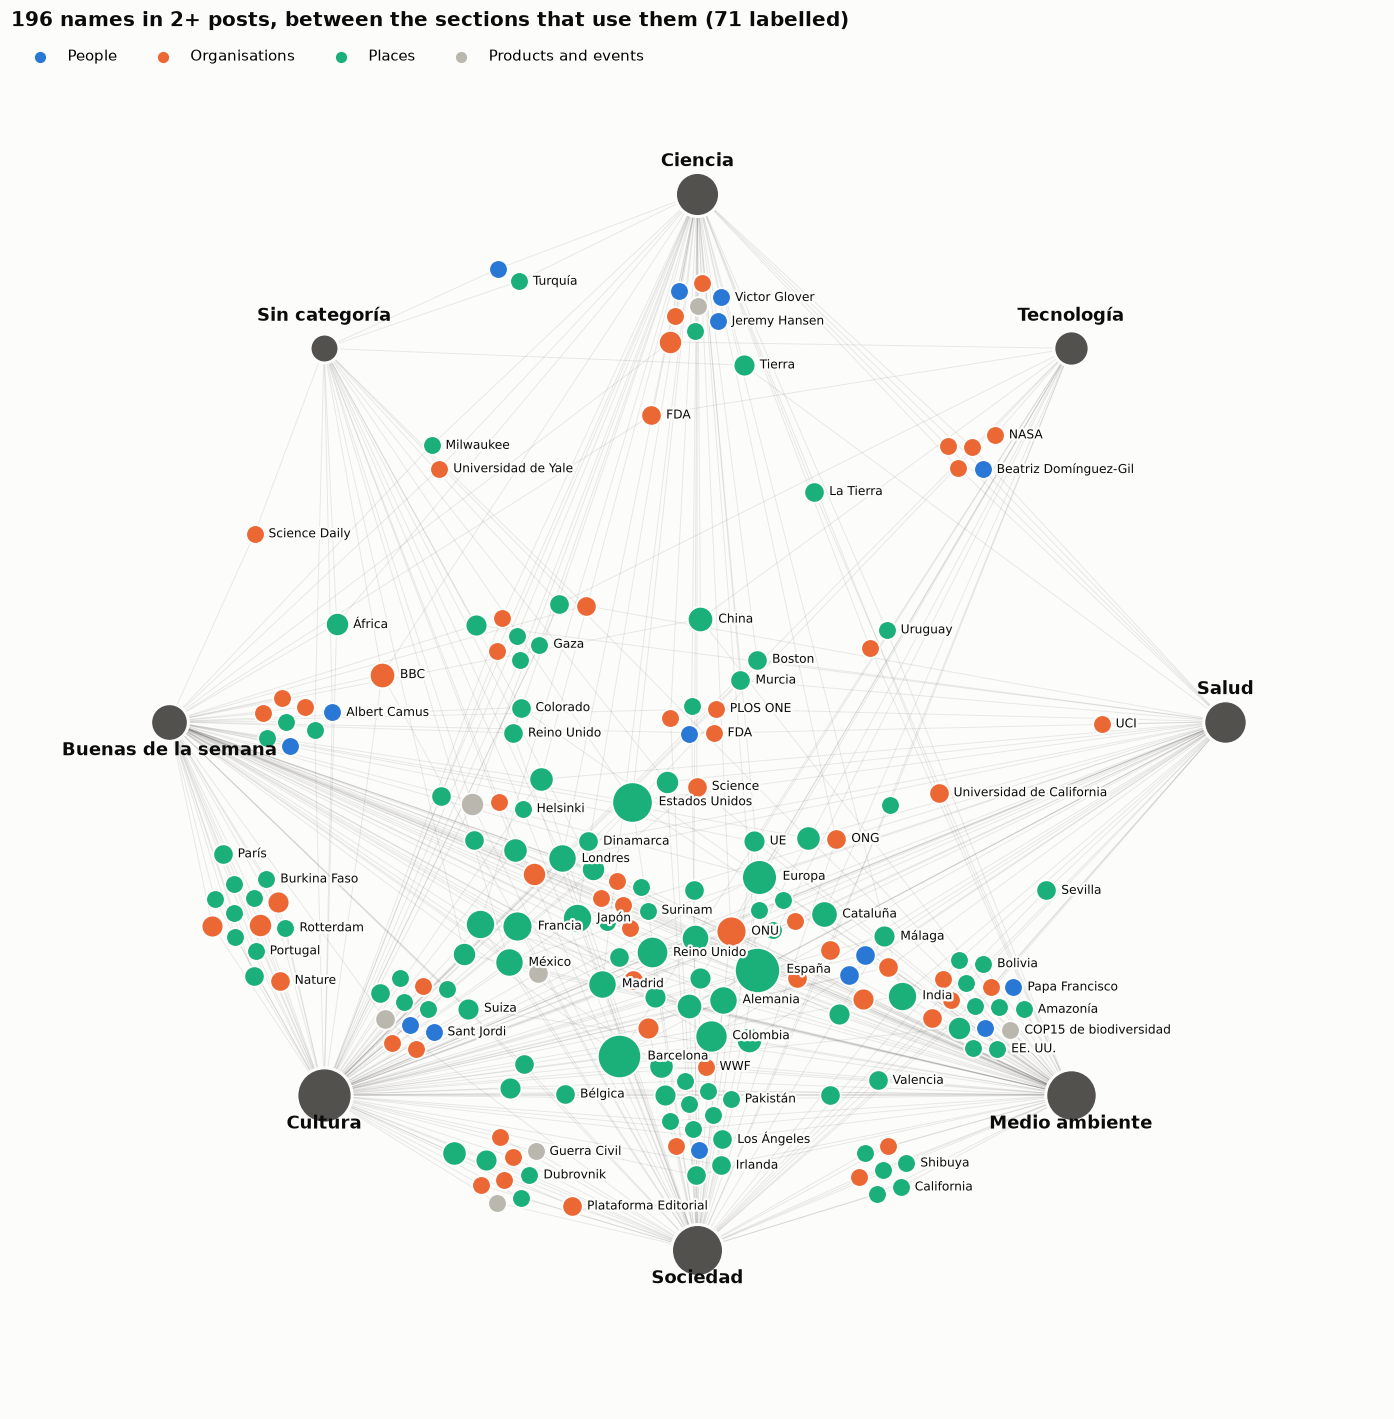

In [29]:
# The same network as a still picture, for a viewer that does not run plotly (GitHub, a PDF).
fig, ax = plt.subplots(figsize=(13, 13))
ax.set_axis_off()
for a, b in G.edges():
    ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color="#52514e", alpha=0.12, linewidth=0.6, zorder=1)
for k in keep:
    kind = kind_of[k]
    ax.scatter(*pos[k], s=(radius[k] * 72 * 13 / 2.8) ** 2 * 3.2, color=KIND_COLOR[kind] if kind in ("people", "organisations", "places") else GREY,
               edgecolors="#fcfcfb", linewidths=1.2, zorder=2)
import matplotlib.patheffects as pe
for k in labelled:
    ax.annotate(name_of[k], (pos[k][0] + radius[k] + 0.006, pos[k][1]), fontsize=8, color=INK, va="center", zorder=4,
                path_effects=[pe.withStroke(linewidth=3, foreground="#fcfcfb")])
for s in SECTIONS:
    x, y = fixed[f"§{s}"]
    ax.scatter(x, y, s=260 + 25 * section_counts[s], color="#52514e", edgecolors="#fcfcfb", linewidths=2, zorder=3)
    ax.annotate(s, (x, y), xytext=(0, 18 if y >= 0 else -22), textcoords="offset points", ha="center", fontsize=12,
                fontweight="bold", color=INK, zorder=5)
for kind, colour in [("People", SLOTS[0]), ("Organisations", SLOTS[1]), ("Places", SLOTS[2]), ("Products and events", GREY)]:
    ax.scatter([], [], s=40, color=colour, label=kind)
ax.legend(loc="upper left", frameon=False, ncol=4)
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 1.3)
ax.set_aspect("equal")
ax.set_title(f"{len(keep)} names in {MIN_POSTS}+ posts, between the sections that use them ({len(labelled)} labelled)", fontsize=13)
fig.tight_layout()

**Reading it:** places connect the sections. Countries and cities (España, Estados Unidos, Barcelona) sit in the middle,
linked to almost every section. 1,906 of the 2,063 names appear in one section only. What recurs beyond places comes
in small clusters around one story told more than once:
- the Artemis II crew (Christina Koch, Jeremy Hansen, Victor Glover, NASA, the Canadian Space Agency, the ISS)
- Shakira, Karol G and the Fundación Con Cora
- UNICEF with Pope Francis

The organisations that cross sections (ONU, BBC, NASA, FDA, Infobae) are mostly cited as sources. One alias, *OMS*
and *Organización Mundial de la Salud*, still counts as two names.

## 7. How the import sits in the rest of the graph

In [30]:
shared_keys = {k: n for k, n in others.items()}
print(f"{len(shared_keys)} of the import's {entities_long['key'].nunique()} entities are also named by one of the graph's other articles.")
pd.DataFrame([{"name": distinct.loc[k, "name"] if k in distinct.index else k, "other articles": n}
              for k, n in sorted(shared_keys.items(), key=lambda kv: -kv[1])]).head(15)

33 of the import's 2383 entities are also named by one of the graph's other articles.


,name,other articles
0,Colombia,3
1,The Conversation,2
2,universidad,1
3,Barcelona,1
4,España,1
5,Portugal,1
6,Sony,1
7,Galicia,1
8,UICN,1
9,Francia,1


## 8. Exports

- `data/wordpress-labels.json`: per post, its categories, tags, WordPress topics and closest topic. The news map
  reads it (`MAP_GRAPH_LABELS`) to show the WordPress labels on each story and to place the posts our classifier left
  without a topic.
- `data/articles.csv`, `data/claims_per_article.csv`, `data/entities.csv`: the tables above.

In [31]:
labels = {
    "source_id": SOURCE_ID,
    "import": IMPORT_DIR.name,
    "written_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "how": "research/wordpress-import/wordpress_import.ipynb, section 4 (TAG_TO_TOPIC, CATEGORY_TO_GROUP, the category fallbacks)",
    "articles": {
        url: {
            "section": str(p["section"]),
            "categories": list(p["categories"]),
            "tags": list(p["tags"]),
            "topics_wordpress": list(p["topics_wordpress"]),
            "wordpress_from": p["wordpress_from"],
            "closest_topic": p["closest_topic"],
            "topic_from": p["topic_from"],
        }
        for url, p in articles.iterrows()
    },
}
(DATA / "wordpress-labels.json").write_text(json.dumps(labels, ensure_ascii=False, indent=1), encoding="utf-8")

flat = articles.copy()
for column in ("categories", "tags", "rejected_for", "topics_classifier", "topics_wordpress"):
    flat[column] = flat[column].map(lambda v: "; ".join(v))
flat.to_csv(DATA / "articles.csv")
claims_per_article.to_csv(DATA / "claims_per_article.csv")
names.assign(posts=names["key"].map(posts))[["url", "section", "key", "name", "type", "kind", "posts"]].to_csv(DATA / "entities.csv", index=False)

print("written:", ", ".join(p.name for p in sorted(DATA.iterdir())))

written: articles.csv, claims_per_article.csv, entities.csv, graph-export.json, wordpress-labels.json
